<a href="https://colab.research.google.com/github/alsedawy/AI/blob/main/FDR_Paper1_Reproduction_Notebook_v002.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# F-D+R Paper 1 — reproduction notebook (source-law retrieval, UAE Arabic/English legal benchmark)

Reproduces the numbers in *Paper1_FDR_Working_Draft* from the input files on Google Drive. Run the cells **in order, one at a time**. A GPU runtime (T4) is required for cells 4–6.

| Cell | What it does | Paper |
|---|---|---|
| 1 | Mount Drive, record library versions | — |
| 2 | Check input files and SHA-256 hashes | — |
| 3 | Truncation check (128-token window) | §4, §7, §8 |
| 4 | Stronger encoders on the frozen 134 cases (control + BGE-M3 + e5-large) | §7, Table A1 |
| 5 | Selection-encoder robustness (e5-base, LaBSE) | §7 |
| 6 | Subset analysis | §7, Table A2 |
| 7 | e5-large diagnostic (precision / prefixes) | §7 |
| 8 | Hit@K by language direction | §7, Table A3 |
| 9 | Figure 7 | §7 |
| 10 | Final check: every paper number against the computed value | — |

**Inputs (not modified):** `legal_benchmark.parquet`, `legal_corpus.parquet`, `FDR_CANDIDATE_EVIDENCE_V001.parquet` (32,333 passages), `FDR_PHASE10_STEP2C_VERIFIED134_RETRIEVAL_RESULTS_v001.parquet` (frozen results), and the human-verified provenance file `FDR_PHASE9_PRODUCTION_RESULTS_v003_CLEAN.csv` (199 reviewed cases, 134 VERIFIED).

**Not reproduced here:** the human review itself (the 134 verified cases are an input, a human decision), the frozen Layer-4 run (its own script and determinism rerun are in the deposit), and the drafting-time figure cells for Figures 2–6.


## Cell 1 — Drive and environment

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import sys, platform, importlib, subprocess
for pkg in ("sentence-transformers","rank_bm25","transformers","torch","pandas","numpy","pyarrow","openpyxl","matplotlib","huggingface_hub"):
    try:
        m=importlib.import_module(pkg.replace('-','_')); print(f"{pkg:22s} {getattr(m,'__version__','?')}")
    except ImportError:
        subprocess.run([sys.executable,'-m','pip','install','-q',pkg]); print(pkg,'installed')
print('python',platform.python_version())
import torch; print('GPU:',torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE (switch to T4 for cells 4-7)')

Mounted at /content/drive
sentence-transformers  5.7.0
rank_bm25 installed
transformers           5.18.0
torch                  2.11.0+cu130
pandas                 2.2.3
numpy                  2.1.3
pyarrow                23.0.1
openpyxl               3.1.5
matplotlib             3.10.0
huggingface_hub        1.33.0
python 3.13.15
GPU: Tesla T4


## Cell 2 — Input files and SHA-256 (record the hashes in the deposit)

In [2]:
import glob, os, hashlib, pandas as pd
def sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for c in iter(lambda:f.read(1<<20),b''): h.update(c)
    return h.hexdigest()
need={"benchmark":("legal_benchmark",".parquet"),"corpus":("legal_corpus",".parquet"),
      "passages":("fdr_candidate_evidence",".parquet"),"frozen results":("verified134_retrieval_results",".parquet"),
      "gold 199/134":("fdr_phase9_production_results_v003_clean",".csv")}
FOUND={}
for k,(pat,ext) in need.items():
    h=[p for p in glob.glob('/content/drive/**/*'+ext,recursive=True) if pat in os.path.basename(p).lower()]
    assert h, "MISSING "+k
    FOUND[k]=h[0]; print(f"{k:15s} {h[0]}\n{'':15s} sha256 {sha(h[0])}")
b=pd.read_parquet(FOUND["benchmark"]); c=pd.read_parquet(FOUND["corpus"])
print('benchmark rows',len(b),'(expected 1285) | corpus laws',len(c),'(expected 390)')
assert len(b)==1285 and len(c)==390
g=pd.read_csv(FOUND["gold 199/134"]); print("gold columns:",g.columns.tolist())
for col in ("benchmark_id","id_low","provenance_status"): assert col in g.columns, "missing column "+col
V=g[g.provenance_status=="VERIFIED"]
print("gold rows",len(g),"| VERIFIED",len(V),"(expected 199 and 134)")
assert len(g)==199 and len(V)==134
r=pd.read_parquet(FOUND["frozen results"])
ids_res=set(r.benchmark_id.astype(str)); ids_gold=set(V.benchmark_id.astype(str))
print("frozen-result cases:",len(ids_res),"| same ids as VERIFIED in gold:",ids_res==ids_gold)
assert ids_res==ids_gold

benchmark       /content/drive/MyDrive/X-AutoAlign_Legal_RAG/00_SOURCE_FILES/legal_benchmark.parquet
                sha256 7ccd167c8122423a4b71f04bab123a6b85b216bd122b8f8a92fbe165a347cc09
corpus          /content/drive/MyDrive/X-AutoAlign_Legal_RAG/00_SOURCE_FILES/legal_corpus.parquet
                sha256 d17a184e9db22908567802193ca4629ede6598f62dcecb36f41f3307ab370eba
passages        /content/drive/MyDrive/F-D+R/DATASET_CONSTRUCTION/FDR_CANDIDATE_EVIDENCE_V001.parquet
                sha256 bd1e3e979ba83721a60797f4c6f4c178ede417a6e7bcd0ebe736382475f6ac55
frozen results  /content/drive/MyDrive/F-D+R/PHASE_10_STEP2C_VERIFIED134_EXECUTION/FDR_PHASE10_STEP2C_VERIFIED134_RETRIEVAL_RESULTS_v001.parquet
                sha256 ecaf353f6a6bb4fa5e8808497e284f04ec4ce643c9a68aa8d7906273a1998e89
gold 199/134    /content/drive/MyDrive/X-AutoAlign_Legal_RAG/01_DATASET_BUILD/FDR_PHASE9_PRODUCTION_RESULTS_v003_CLEAN.csv
                sha256 b9ce9d79bdf162e83e93bf5432b6f9a2e4531ec2e745e6a70ae4c414

## Cell 3 — Truncation check (128 tokens)

In [3]:
# Colab cell: how many STEP 1G chunks exceed the 128-token input limit of paraphrase-multilingual-MiniLM-L12-v2?
# Read-only. Uses the same chunking rule as STEP 1G (3,000 chars, 400 overlap, whitespace-normalised).
import re, glob, os, numpy as np, pandas as pd
from transformers import AutoTokenizer
def find(pat):
    h=[p for p in glob.glob("/content/**/*.parquet",recursive=True) if pat in os.path.basename(p).lower()]
    return h[0] if h else None
C=find("corpus")
if C is None:
    from google.colab import files; files.upload(); C=find("corpus")
corpus=pd.read_parquet(C); print("corpus rows:",len(corpus),list(corpus.columns))
norm=lambda t: re.sub(r"\s+"," ",t.strip()) if isinstance(t,str) else ""
def chunk_document(text):
    text=norm(text)
    if not text: return []
    if len(text)<=3000: return [text]
    out=[];s=0
    while s<len(text):
        e=min(s+3000,len(text)); c=text[s:e].strip()
        if c: out.append(c)
        if e>=len(text): break
        s=e-400
    return out
chunks=[(str(r.law_id),str(r.language).lower().strip(),c) for r in corpus.itertuples() for c in chunk_document(str(r.title)+"\n"+str(r.content))]  # STEP 1G chunks title + newline + content
df=pd.DataFrame(chunks,columns=["law_id","language","text"]); print("chunks:",len(df),"(expected 3,625)")
tok=AutoTokenizer.from_pretrained("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",revision="e8f8c211226b894fcb81acc59f3b34ba3efd5f42")
df["tokens"]=[len(x) for x in tok(df.text.tolist(),add_special_tokens=True,truncation=False)["input_ids"]]
def rep(d,name):
    print(f"\n{name}: n={len(d)} | mean={d.tokens.mean():.0f} median={d.tokens.median():.0f} p10={d.tokens.quantile(.1):.0f} p90={d.tokens.quantile(.9):.0f}"
          f" | > 128 tokens: {(d.tokens>128).sum()} ({(d.tokens>128).mean()*100:.1f}%) | share of text kept (128/tokens): {np.minimum(128/d.tokens,1).mean()*100:.1f}%")
rep(df,"ALL chunks")
for lang,g in df.groupby("language"): rep(g,f"language={lang}")
df.drop(columns="text").to_csv("chunk_token_lengths.csv",index=False)
print("\nsaved chunk_token_lengths.csv")
# Layer-4 passages (32,333): if a passage file is on Drive, repeat the report for it
P=[p for p in glob.glob("/content/drive/**/*.parquet",recursive=True) if "passage" in os.path.basename(p).lower()]
print("\npassage-file candidates on Drive:",P[:10])


corpus rows: 390 ['law_id', 'language', 'title', 'content']
chunks: 3625 (expected 3,625)


config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/526 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (868 > 512). Running this sequence through the model will result in indexing errors



ALL chunks: n=3625 | mean=702 median=686 p10=598 p90=883 | > 128 tokens: 3603 (99.4%) | share of text kept (128/tokens): 20.4%

language=arabic: n=1393 | mean=803 median=853 p10=572 p90=913 | > 128 tokens: 1387 (99.6%) | share of text kept (128/tokens): 18.3%

language=english: n=2232 | mean=640 median=661 p10=599 p90=713 | > 128 tokens: 2216 (99.3%) | share of text kept (128/tokens): 21.6%

saved chunk_token_lengths.csv

passage-file candidates on Drive: []


## Cell 4 — Stronger encoders on the frozen 134 cases (GPU, about 8 minutes)

In [4]:
# ===================================================================
# Colab cell: do the 134 verified cases give the same ordering with STRONGER, INDEPENDENT encoders?
#   - cohort is NOT changed (the frozen 134); only the dense retriever is swapped (BGE-M3, mE5-large)
#   - the same passages, the same BM25, the same RRF (k=60, equal weights, top-100 each, top-20)
#   - a CONTROL step first re-runs the original MiniLM and must reproduce the frozen numbers
#     (dense 73/113/126/128, hybrid 6/50/84/119, BM25 0/0/0/1); if it does not, the script stops
# Read-only on all inputs. Nothing in the frozen protocol is modified.
# RUNTIME: GPU required (Runtime > Change runtime type > T4 GPU). Needs internet (Hugging Face).
# FILES (upload when asked):
#   legal_benchmark*.parquet, FDR_PHASE10_STEP2C_VERIFIED134_RETRIEVAL_RESULTS_v001.parquet,
#   the PASSAGE table used by STEP2C (a parquet/csv that has a `passage_id` column and the passage text),
#   legal_corpus*.parquet  (only to map law -> language)
# ===================================================================
import re, glob, os, math, sys, subprocess, numpy as np, pandas as pd
for pkg,imp in (("sentence-transformers","sentence_transformers"),("rank_bm25","rank_bm25")):
    try: __import__(imp)
    except ImportError: subprocess.run([sys.executable,"-m","pip","install","-q",pkg])
from sentence_transformers import SentenceTransformer
from rank_bm25 import BM25Okapi
from huggingface_hub import model_info
import torch
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > T4 GPU, then run again."

def find(*pats, exts=(".parquet",)):
    hs=[p for p in glob.glob("/content/**/*",recursive=True) if p.lower().endswith(exts) and all(x in os.path.basename(p).lower() for x in pats)]
    return hs[0] if hs else None
def find_passages():
    for p in glob.glob("/content/**/*",recursive=True):
        if p.lower().endswith((".parquet",".csv")) and not any(x in os.path.basename(p).lower() for x in ("verified134_retrieval_results","benchmark","corpus")):
            try:
                df=pd.read_parquet(p) if p.endswith(".parquet") else pd.read_csv(p,nrows=5)
            except Exception: continue
            if "passage_id" in df.columns and any(c in df.columns for c in ("text","passage_text","content","passage")): return p
    return None
need={"bench":lambda:find("benchmark"),"corpus":lambda:find("corpus"),"res":lambda:find("verified134_retrieval_results"),"pass":find_passages}
paths={k:f() for k,f in need.items()}
if any(v is None for v in paths.values()):
    from google.colab import files
    print("Missing:",[k for k,v in paths.items() if v is None],"-> select the files now"); files.upload()
    paths={k:f() for k,f in need.items()}
assert all(paths.values()), ("still missing:",paths)
print(paths)

# ---------- data ----------
corpus=pd.read_parquet(paths["corpus"]); bench=pd.read_parquet(paths["bench"]).reset_index(drop=True)
bench["benchmark_id"]=[f"B{i+1:04d}" for i in range(len(bench))]
res=pd.read_parquet(paths["res"])
res["hit_law"]=res.passage_id.astype(str).str.split("__").str[0].apply(lambda x: str(int(float(x))))
res["tgt"]=res.target_id_low.apply(lambda x: str(int(float(x)))); res["is_hit"]=(res.hit_law==res.tgt)
print("frozen rows:",len(res),"| conditions:",sorted(res.condition.unique()),"| cases:",res.benchmark_id.nunique())
cases=res.drop_duplicates("benchmark_id")[["benchmark_id","tgt","language_direction"]].set_index("benchmark_id")
q=bench.set_index("benchmark_id").loc[cases.index,"question"].astype(str).str.strip().str.replace(r"\s+"," ",regex=True)
assert len(cases)==134, len(cases)

pas=pd.read_parquet(paths["pass"]) if paths["pass"].endswith(".parquet") else pd.read_csv(paths["pass"])
tcol=[c for c in ("text","passage_text","content","passage") if c in pas.columns][0]
pas=pas[["passage_id",tcol]].rename(columns={tcol:"text"}); pas["passage_id"]=pas.passage_id.astype(str)
pas=pas.sort_values("passage_id",kind="mergesort").reset_index(drop=True)
pas["law"]=pas.passage_id.str.split("__").str[0].apply(lambda x: str(int(float(x))))
lang=dict(zip(corpus.law_id.astype(str).apply(lambda x:str(int(float(x)))),corpus.language.astype(str).str.lower().str.strip()))
pas["lang"]=pas.law.map(lang).apply(lambda x: "english" if str(x).startswith("en") else ("arabic" if str(x).startswith("ar") else str(x)))
print("passages:",len(pas),"| laws:",pas.law.nunique(),"| language share:",pas.lang.value_counts(dropna=False).to_dict())
assert pas.passage_id.is_unique and pas.text.notna().all()
frozen_ids=set(res.passage_id.astype(str)); print("frozen retrieved passages present in the passage table:",len(frozen_ids&set(pas.passage_id)),"of",len(frozen_ids))
assert frozen_ids<=set(pas.passage_id), "passage table does not contain the passages the frozen run retrieved -> wrong file"

# ---------- helpers ----------
def topk_order(scores,k,pids):
    # sort by (-score, passage_id); pids is already sorted ascending, mergesort is stable -> deterministic tie-break on passage_id
    return np.argsort(-scores,kind="mergesort")[:k]
def rrf(r1,r2,k=60,top=20):
    sc={}
    for r in (r1,r2):
        for rank,i in enumerate(r,1): sc[i]=sc.get(i,0.0)+1.0/(k+rank)
    return sorted(sc,key=lambda i:(-sc[i],pas.passage_id.iat[i]))[:top]
def wilson(k,n,z=1.96):
    p=k/n; d=1+z*z/n; c=(p+z*z/(2*n))/d; h=z*math.sqrt(p*(1-p)/n+z*z/(4*n*n))/d; return c-h,c+h
tgt=cases.tgt.to_dict(); ids=list(cases.index)
plaw=pas.law.values; plang=pas.lang.values
def hits(lists,K): return {b:any(plaw[i]==tgt[b] for i in lists[b][:K]) for b in ids}
def table(name,lists):
    row={"system":name}
    for K in (1,5,10,20):
        k=sum(hits(lists,K).values()); lo,hi=wilson(k,134); row[f"K{K}"]=f"{k}/134 = {100*k/134:.1f}% [{100*lo:.1f}-{100*hi:.1f}]"
    qlang={"EN→AR":"english","AR→EN":"arabic"}
    sh=np.mean([np.mean([plang[i]==qlang.get(cases.language_direction[b],"") for i in lists[b][:20]]) for b in ids])
    row["share_top20_in_query_language"]=f"{100*sh:.1f}%"; return row

# ---------- BM25 (frozen settings) ----------
bm=BM25Okapi([t.lower().split() for t in pas.text],k1=1.5,b=0.75,epsilon=0.25)
bm_scores={b:bm.get_scores(q[b].lower().split()) for b in ids}
bm_top100={b:list(topk_order(bm_scores[b],100,None)) for b in ids}

# ---------- dense with a given model ----------
def dense_run(name,qp="",pp="",rev=None,max_len=512):
    sha=rev or model_info(name).sha; print(f"\n=== {name} | revision {sha}")
    m=SentenceTransformer(name,revision=sha,device="cuda"); m.max_seq_length=max_len
    if "MiniLM" not in name: m.half()      # control stays in float32 like the frozen run
    tk=m.tokenizer; L=np.array([len(x) for x in tk([pp+t for t in pas.text.tolist()],truncation=False)["input_ids"]])
    print(f"max_seq_length {m.max_seq_length} | passages over the limit: {(L>m.max_seq_length).mean()*100:.2f}% | mean share of text kept: {np.minimum(m.max_seq_length/L,1).mean()*100:.1f}%")
    E=m.encode([pp+t for t in pas.text.tolist()],batch_size=64,normalize_embeddings=True,show_progress_bar=True,convert_to_numpy=True)
    Q=m.encode([qp+q[b] for b in ids],batch_size=32,normalize_embeddings=True,convert_to_numpy=True)
    S=Q.astype(np.float32)@E.astype(np.float32).T
    d100={b:list(topk_order(S[j],100,None)) for j,b in enumerate(ids)}
    del m,E; torch.cuda.empty_cache(); return sha,d100

MODELS=[("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2","","","e8f8c211226b894fcb81acc59f3b34ba3efd5f42",128),  # CONTROL
        ("BAAI/bge-m3","","",None,1024),
        ("intfloat/multilingual-e5-large","query: ","passage: ",None,512)]
rows=[]; allruns={}
ctrl_ok=None
for name,qp,pp,rev,ml in MODELS:
    sha,d100=dense_run(name,qp,pp,rev,ml); short=name.split("/")[-1]
    dense={b:d100[b][:20] for b in ids}
    fus={b:rrf(bm_top100[b],d100[b]) for b in ids}
    allruns[short]=(dense,fus)
    if "MiniLM" in name:
        rows += [table("BM25 (recomputed)",{b:bm_top100[b][:20] for b in ids}), table(f"{short} dense [CONTROL]",dense), table(f"BM25+{short} RRF [CONTROL]",fus)]
        got=[sum(hits(dense,K).values()) for K in (1,5,10,20)]; gotf=[sum(hits(fus,K).values()) for K in (1,5,10,20)]
        print("CONTROL dense K=1,5,10,20:",got,"(frozen: [73,113,126,128]) | hybrid:",gotf,"(frozen: [6,50,84,119])")
        ctrl_ok=(got==[73,113,126,128])
        # also compare with the frozen lists directly
        fz={c:{b:list(res[(res.condition==c)&(res.benchmark_id==b)].sort_values("rank").passage_id.astype(str)) for b in ids} for c in ("C2_DENSE","C3_HYBRID_RRF")}
        same=sum(fz["C2_DENSE"][b]==[pas.passage_id.iat[i] for i in dense[b]] for b in ids)
        print(f"CONTROL: dense top-20 lists identical to the frozen lists in {same}/134 cases")
        if not ctrl_ok:
            print("\n*** CONTROL FAILED: the passage table or query text differs from the frozen run. Stop here and send me this output. ***")
            pd.DataFrame(rows).to_csv("stronger_encoder_summary_CONTROL_FAILED.csv",index=False); raise SystemExit
    else:
        rows += [table(f"{short} dense",dense), table(f"BM25+{short} RRF",fus)]
    print(pd.DataFrame(rows).to_string(index=False))

# ---------- paired comparison with the original dense (descriptive) ----------
from math import comb
def mcnemar_exact(a,b):
    n=a+b;
    if n==0: return 1.0
    k=min(a,b); p=sum(comb(n,i) for i in range(0,k+1))/2**n; return min(1.0,2*p)
base=allruns["paraphrase-multilingual-MiniLM-L12-v2"][0]
print("\n--- paired vs original MiniLM dense (descriptive; discordant = cases where exactly one hits)")
for short,(dense,fus) in allruns.items():
    if "MiniLM" in short: continue
    for K in (1,20):
        h0=hits(base,K); h1=hits(dense,K); only1=sum(h1[b] and not h0[b] for b in ids); only0=sum(h0[b] and not h1[b] for b in ids)
        print(f"{short} dense vs MiniLM dense, K={K}: only-new {only1}, only-MiniLM {only0}, exact McNemar p={mcnemar_exact(only1,only0):.3g}")
pc=[]
for short,(dense,fus) in allruns.items():
    for sysname,lists in ((short+"|dense",dense),(short+"|fusion",fus)):
        h1,h20=hits(lists,1),hits(lists,20)
        for b in ids: pc.append({"benchmark_id":b,"system":sysname,"hit_K1":int(h1[b]),"hit_K20":int(h20[b]),"direction":cases.language_direction[b]})
pd.DataFrame(pc).to_csv("per_case_hits.csv",index=False); print("saved per_case_hits.csv")
out=pd.DataFrame(rows); out.to_csv("stronger_encoder_summary.csv",index=False)
print("\nFINAL TABLE"); print(out.to_string(index=False)); print("saved stronger_encoder_summary.csv")


{'bench': '/content/drive/MyDrive/X-AutoAlign_Legal_RAG/00_SOURCE_FILES/legal_benchmark.parquet', 'corpus': '/content/drive/MyDrive/X-AutoAlign_Legal_RAG/00_SOURCE_FILES/legal_corpus.parquet', 'res': '/content/drive/MyDrive/F-D+R/PHASE_10_STEP2C_VERIFIED134_EXECUTION/FDR_PHASE10_STEP2C_VERIFIED134_RETRIEVAL_RESULTS_v001.parquet', 'pass': '/content/drive/MyDrive/F-D+R/DATASET_CONSTRUCTION/FDR_CANDIDATE_EVIDENCE_V001.parquet'}
frozen rows: 8040 | conditions: ['C1_BM25', 'C2_DENSE', 'C3_HYBRID_RRF'] | cases: 134
passages: 32333 | laws: 390 | language share: {'english': 17977, 'arabic': 14356}
frozen retrieved passages present in the passage table: 3989 of 3989

=== sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 | revision e8f8c211226b894fcb81acc59f3b34ba3efd5f42


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/201 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (981 > 512). Running this sequence through the model will result in indexing errors


max_seq_length 512 | passages over the limit: 1.35% | mean share of text kept: 99.7%


Batches:   0%|          | 0/506 [00:00<?, ?it/s]

                                                  system                         K1                          K5                         K10                         K20 share_top20_in_query_language
                                       BM25 (recomputed)     0/134 = 0.0% [0.0-2.8]      0/134 = 0.0% [0.0-2.8]      0/134 = 0.0% [0.0-2.8]      1/134 = 0.7% [0.1-4.1]                         99.8%
   paraphrase-multilingual-MiniLM-L12-v2 dense [CONTROL] 73/134 = 54.5% [46.0-62.7] 113/134 = 84.3% [77.2-89.5] 126/134 = 94.0% [88.7-96.9] 128/134 = 95.5% [90.6-97.9]                         37.7%
BM25+paraphrase-multilingual-MiniLM-L12-v2 RRF [CONTROL]     6/134 = 4.5% [2.1-9.4]  50/134 = 37.3% [29.6-45.7]  84/134 = 62.7% [54.3-70.4] 119/134 = 88.8% [82.4-93.1]                         73.7%
                                            bge-m3 dense 59/134 = 44.0% [35.9-52.5]  95/134 = 70.9% [62.7-77.9] 109/134 = 81.3% [73.9-87.0] 118/134 = 88.1% [81.5-92.5]                         63.0%
          

## Cell 5 — Selection-encoder robustness (GPU)

In [5]:
# ===================================================================
# Colab cell: does the result survive when the semantic-consensus step uses an INDEPENDENT encoder?
# Read-only on all inputs. Does NOT re-run BM25/dense/RRF: it re-uses the frozen Layer-4 result file and
# recomputes Hit@K on the sub-sample of the 134 verified cases that the new encoder ALSO selects.
# Use a GPU runtime (Runtime > Change runtime type > T4). Needs internet (Hugging Face downloads).
# Files needed (upload when asked, or keep on Drive):  legal_corpus*.parquet, legal_benchmark*.parquet,
#   FDR_PHASE9_PRODUCTION_RESULTS_v003_CLEAN.csv, FDR_PHASE10_STEP2C_VERIFIED134_RETRIEVAL_RESULTS_v001.parquet
# ===================================================================
import re, glob, os, math, numpy as np, pandas as pd
import subprocess, sys
try: import sentence_transformers
except ImportError: subprocess.run([sys.executable,"-m","pip","install","-q","sentence-transformers"])
from sentence_transformers import SentenceTransformer
from huggingface_hub import model_info
import torch

def find(*pats, ext):
    hs=[p for p in glob.glob("/content/**/*"+ext,recursive=True) if all(x in os.path.basename(p).lower() for x in pats)]
    return hs[0] if hs else None
need={"corpus":("corpus",".parquet"),"bench":("benchmark",".parquet"),"gold":("fdr_phase9_production_results_v003_clean",".csv"),"res":("verified134_retrieval_results",".parquet")}
paths={k:find(v[0],ext=v[1]) for k,v in need.items()}
if any(v is None for v in paths.values()):
    from google.colab import files
    print("Missing:",[k for k,v in paths.items() if v is None],"-> select the files now"); files.upload()
    paths={k:find(v[0],ext=v[1]) for k,v in need.items()}
assert all(paths.values()), paths
print(paths)

# ---------- data (same preparation as STEP 1G) ----------
corpus=pd.read_parquet(paths["corpus"]); bench=pd.read_parquet(paths["bench"]).reset_index(drop=True)
bench["benchmark_id"]=[f"B{i+1:04d}" for i in range(len(bench))]          # same ids as STEP 1G
for c in ("user_language","supporting_document_language"): bench[c]=bench[c].astype(str).str.lower().str.strip()
cl=bench[bench.user_language!=bench.supporting_document_language].copy(); print("cross-lingual rows:",len(cl),"(expected 663)")
norm=lambda t: re.sub(r"\s+"," ",t.strip()) if isinstance(t,str) else ""
def chunk_document(text):
    text=norm(text)
    if not text: return []
    if len(text)<=3000: return [text]
    out=[];s=0
    while s<len(text):
        e=min(s+3000,len(text)); c=text[s:e].strip()
        if c: out.append(c)
        if e>=len(text): break
        s=e-400
    return out
rows=[]
for r in corpus.itertuples():
    for k,c in enumerate(chunk_document(str(r.title)+"\n"+str(r.content))): rows.append((str(r.law_id),str(r.language).lower().strip(),k,c))
ch=pd.DataFrame(rows,columns=["law_id","language","chunk_id","text"]); print("chunks:",len(ch),"(expected 3,625)")

gold=pd.read_csv(paths["gold"])
gold["bid"]=gold.benchmark_id.astype(str)
old199=set(gold.bid); ver=gold[gold.provenance_status=="VERIFIED"].copy()
ver["human_law"]=ver.id_low.apply(lambda x: str(int(float(x))))
ver_law=dict(zip(ver.bid,ver.human_law)); ver_ids=set(ver_law); print("old candidates:",len(old199),"verified:",len(ver_ids))

res=pd.read_parquet(paths["res"]); print("frozen result rows:",len(res),"| conditions:",sorted(res.condition.unique()))
res["hit_law"]=res.law_id.apply(lambda x: str(int(float(x)))); res["tgt"]=res.target_id_low.apply(lambda x: str(int(float(x))))
res["is_hit"]=(res.hit_law==res.tgt)

# ---------- consensus with a given encoder ----------
def consensus(name, q_prefix="", p_prefix="", revision=None):
    sha=revision or model_info(name).sha
    print(f"\n=== {name} | revision {sha}")
    m=SentenceTransformer(name,revision=sha,device="cuda" if torch.cuda.is_available() else "cpu")
    print("max_seq_length:",m.max_seq_length)
    tk=m.tokenizer; lens=np.array([len(x) for x in tk([p_prefix+t for t in ch.text.tolist()],truncation=False)["input_ids"]])
    print(f"chunks longer than the model limit: {(lens>m.max_seq_length).mean()*100:.1f}% | mean share of text kept: {np.minimum(m.max_seq_length/lens,1).mean()*100:.1f}%")
    E=m.encode([p_prefix+t for t in ch.text.tolist()],batch_size=32,normalize_embeddings=True,show_progress_bar=True,convert_to_numpy=True)
    top1={}   # (bid,path)->law
    for dlang,g in cl.groupby("supporting_document_language"):
        idx=np.where(ch.language.values==dlang)[0]; laws=ch.law_id.values[idx]
        order=np.argsort(laws,kind="stable"); idx=idx[order]; laws=laws[order]          # group chunks by law
        starts=np.r_[0,np.where(laws[1:]!=laws[:-1])[0]+1]; ulaw=laws[starts]
        for path,fn in (("Q",lambda r:norm(r.question)),("A",lambda r:norm(r.answer)),("QA",lambda r:norm(r.question)+"\n"+norm(r.answer))):
            texts=[q_prefix+fn(r) for r in g.itertuples()]
            Q=m.encode(texts,batch_size=32,normalize_embeddings=True,convert_to_numpy=True)
            S=Q@E[idx].T; D=np.maximum.reduceat(S,starts,axis=1); best=ulaw[D.argmax(axis=1)]
            for b,l in zip(g.benchmark_id,best): top1[(b,path)]=l
    cons={}
    for b in cl.benchmark_id:
        t=[top1[(b,p)] for p in ("Q","A","QA")]
        if t[0]==t[1]==t[2]: cons[b]=t[0]
    del m; torch.cuda.empty_cache()
    return cons

def wilson(k,n,z=1.96):
    if n==0: return (float("nan"),)*2
    p=k/n; d=1+z*z/n; c=(p+z*z/(2*n))/d; h=z*math.sqrt(p*(1-p)/n+z*z/(4*n*n))/d; return c-h,c+h
def hit_table(ids,label):
    sub=res[res.benchmark_id.isin(ids)]; n=sub.benchmark_id.nunique(); out=[]
    for cond in ("C1_BM25","C2_DENSE","C3_HYBRID_RRF"):
        row={"cond":cond}
        for K in (1,5,10,20):
            h=sub[(sub.condition==cond)&(sub["rank"]<=K)].groupby("benchmark_id").is_hit.any().reindex(sorted(ids)).fillna(False)
            k=int(h.sum()); lo,hi=wilson(k,n); row[f"K{K}"]=f"{k}/{n} = {100*k/n:.1f}% [{100*lo:.1f}-{100*hi:.1f}]"
        out.append(row)
    print(f"\n--- Hit@K (law level), {label}, n={n}"); print(pd.DataFrame(out).to_string(index=False))

# ---------- run: control (original encoder) + two independent encoders ----------
MODELS=[("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2","","","e8f8c211226b894fcb81acc59f3b34ba3efd5f42"),  # control: must reproduce the 199
        ("intfloat/multilingual-e5-base","query: ","passage: ",None),
        ("sentence-transformers/LaBSE","","",None)]
summary=[]
hit_table(ver_ids,"ALL 134 verified (frozen result, reference)")
for name,qp,pp,rev in MODELS:
    cons=consensus(name,qp,pp,rev); ids=set(cons)
    pd.DataFrame({'benchmark_id':sorted(ids),'consensus_law':[cons[b] for b in sorted(ids)]}).to_csv(f"consensus_ids_{name.split('/')[-1]}.csv",index=False)   # saved for the subset analysis
    inter_old=ids&old199; inter_ver=ids&ver_ids
    agree_h=sum(cons[b]==ver_law[b] for b in inter_ver)
    print(f"\n{name}: consensus candidates {len(ids)} | overlap with the old 199: {len(inter_old)} | "
          f"overlap with the 134 verified: {len(inter_ver)} of 134 | its consensus law = human law in {agree_h} of those")
    if "MiniLM" in name: print("CONTROL CHECK -> new set equals the old 199:", ids==old199)
    hit_table(inter_ver,f"134 verified AND selected by {name.split('/')[-1]}")
    summary.append({"encoder":name.split('/')[-1],"candidates":len(ids),"overlap_old199":len(inter_old),"overlap_verified134":len(inter_ver),"consensus_law==human_law":agree_h})
print("\n",pd.DataFrame(summary).to_string(index=False))
pd.DataFrame(summary).to_csv("alt_encoder_summary.csv",index=False); print("saved alt_encoder_summary.csv")


{'corpus': '/content/drive/MyDrive/X-AutoAlign_Legal_RAG/00_SOURCE_FILES/legal_corpus.parquet', 'bench': '/content/drive/MyDrive/X-AutoAlign_Legal_RAG/00_SOURCE_FILES/legal_benchmark.parquet', 'gold': '/content/drive/MyDrive/X-AutoAlign_Legal_RAG/01_DATASET_BUILD/FDR_PHASE9_PRODUCTION_RESULTS_v003_CLEAN.csv', 'res': '/content/drive/MyDrive/F-D+R/PHASE_10_STEP2C_VERIFIED134_EXECUTION/FDR_PHASE10_STEP2C_VERIFIED134_RETRIEVAL_RESULTS_v001.parquet'}
cross-lingual rows: 663 (expected 663)
chunks: 3625 (expected 3,625)
old candidates: 199 verified: 134
frozen result rows: 8040 | conditions: ['C1_BM25', 'C2_DENSE', 'C3_HYBRID_RRF']

--- Hit@K (law level), ALL 134 verified (frozen result, reference), n=134
         cond                         K1                          K5                         K10                         K20
      C1_BM25     0/134 = 0.0% [0.0-2.8]      0/134 = 0.0% [0.0-2.8]      0/134 = 0.0% [0.0-2.8]      1/134 = 0.7% [0.1-4.1]
     C2_DENSE 73/134 = 54.5% [46.0-62.7] 1

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

max_seq_length: 128


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (868 > 128). Running this sequence through the model will result in indexing errors


chunks longer than the model limit: 99.4% | mean share of text kept: 20.4%


...

max_seq_length: 256


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (894 > 256). Running this sequence through the model will result in indexing errors


chunks longer than the model limit: 96.7% | mean share of text kept: 40.9%


Batches:   0%|          | 0/114 [00:00<?, ?it/s]


sentence-transformers/LaBSE: consensus candidates 216 | overlap with the old 199: 81 | overlap with the 134 verified: 70 of 134 | its consensus law = human law in 66 of those

--- Hit@K (law level), 134 verified AND selected by LaBSE, n=70
         cond                        K1                        K5                       K10                         K20
      C1_BM25     0/70 = 0.0% [0.0-5.2]     0/70 = 0.0% [0.0-5.2]     0/70 = 0.0% [0.0-5.2]       1/70 = 1.4% [0.3-7.7]
     C2_DENSE 47/70 = 67.1% [55.5-77.0] 65/70 = 92.9% [84.3-96.9] 68/70 = 97.1% [90.2-99.2] 70/70 = 100.0% [94.8-100.0]
C3_HYBRID_RRF    5/70 = 7.1% [3.1-15.7] 32/70 = 45.7% [34.6-57.3] 49/70 = 70.0% [58.5-79.5]   65/70 = 92.9% [84.3-96.9]

                               encoder  candidates  overlap_old199  overlap_verified134  consensus_law==human_law
paraphrase-multilingual-MiniLM-L12-v2         199             199                  134                       134
                 multilingual-e5-base         300  

## Cell 6 — Subset analysis (needs the outputs of cells 4 and 5)

In [6]:
# ===================================================================
# Colab cell (CPU is enough, seconds): is the lower score of the stronger encoders a SELECTION effect?
# Compares dense hit rates on subsets of the frozen 134 defined by WHICH encoders independently select the case.
# No new human review needed; nothing in the frozen protocol changes.
# Needs (from the two earlier cells, same Colab session or upload them):
#   per_case_hits.csv                  <- STRONGER_ENCODER_RETRIEVAL_CHECK.py (re-run it once; it now saves this)
#   consensus_ids_multilingual-e5-base.csv, consensus_ids_LaBSE.csv  <- ALT_ENCODER_CONSENSUS_CHECK.py (re-run once)
#   consensus_ids_paraphrase-multilingual-MiniLM-L12-v2.csv  (same cell: MiniLM control)
#   FDR_PHASE10_STEP2C_VERIFIED134_RETRIEVAL_RESULTS_v001.parquet  (only to list the 134 ids)
# ===================================================================
import glob, os, math, pandas as pd
def f(p):
    h=[x for x in glob.glob("/content/**/*",recursive=True) if os.path.basename(x).lower()==p.lower()]; return h[0] if h else None
def fres():
    h=[x for x in glob.glob("/content/**/*",recursive=True) if "verified134_retrieval_results" in os.path.basename(x).lower() and x.lower().endswith(".parquet")]; return h[0] if h else None
names=["per_case_hits.csv","consensus_ids_multilingual-e5-base.csv","consensus_ids_LaBSE.csv","consensus_ids_paraphrase-multilingual-MiniLM-L12-v2.csv"]
miss=[n for n in names if f(n) is None]
if miss:
    raise SystemExit("STOP: these files do not exist yet: "+str(miss)+"\nThey are OUTPUTS of the two earlier cells. Run, in this same Colab session and in this order: (1) ALT_ENCODER_CONSENSUS_CHECK.py  (2) STRONGER_ENCODER_RETRIEVAL_CHECK.py  (both on GPU), then run this cell again. Do not upload anything for them.")
res=[fres()] if fres() else []
if not res:
    from google.colab import files; print("select the STEP2C results parquet"); files.upload(); res=[fres()]
assert res[0], "results parquet not found"
ids134=sorted(pd.read_parquet(res[0]).benchmark_id.unique()); assert len(ids134)==134
pc=pd.read_csv(f(names[0]))
sel={k:set(pd.read_csv(f(n)).benchmark_id) for k,n in (("MiniLM",names[3]),("e5b",names[1]),("LaBSE",names[2]))}
def wilson(k,n,z=1.96):
    p=k/n; d=1+z*z/n; c=(p+z*z/(2*n))/d; h=z*math.sqrt(p*(1-p)/n+z*z/(4*n*n))/d; return c-h,c+h
subsets={"all 134":set(ids134),
 "selected by MiniLM+e5b+LaBSE (3 families agree)":set(ids134)&sel["e5b"]&sel["LaBSE"],
 "selected by MiniLM only (neither e5b nor LaBSE)":set(ids134)-sel["e5b"]-sel["LaBSE"],
 "selected by e5b or LaBSE":set(ids134)&(sel["e5b"]|sel["LaBSE"])}
rows=[]
for sn,S in subsets.items():
    for system in ("paraphrase-multilingual-MiniLM-L12-v2|dense","bge-m3|dense","multilingual-e5-large|dense","bge-m3|fusion","multilingual-e5-large|fusion","paraphrase-multilingual-MiniLM-L12-v2|fusion"):
        g=pc[(pc.system==system)&pc.benchmark_id.isin(S)]; n=len(g)
        if n==0: continue
        r={"subset":sn,"n":n,"system":system}
        for K in (1,20):
            k=int(g[f"hit_K{K}"].sum()); lo,hi=wilson(k,n); r[f"K{K}"]=f"{k}/{n} = {100*k/n:.1f}% [{100*lo:.1f}-{100*hi:.1f}]"
        rows.append(r)
out=pd.DataFrame(rows); pd.set_option("display.width",250); print(out.to_string(index=False)); out.to_csv("subset_analysis.csv",index=False)


                                         subset   n                                       system                         K1                         K20
                                        all 134 134  paraphrase-multilingual-MiniLM-L12-v2|dense 73/134 = 54.5% [46.0-62.7] 128/134 = 95.5% [90.6-97.9]
                                        all 134 134                                 bge-m3|dense 59/134 = 44.0% [35.9-52.5] 118/134 = 88.1% [81.5-92.5]
                                        all 134 134                  multilingual-e5-large|dense   12/134 = 9.0% [5.2-15.0]  74/134 = 55.2% [46.8-63.4]
                                        all 134 134                                bge-m3|fusion     1/134 = 0.7% [0.1-4.1]  97/134 = 72.4% [64.3-79.3]
                                        all 134 134                 multilingual-e5-large|fusion     0/134 = 0.0% [0.0-2.8]  40/134 = 29.9% [22.8-38.1]
                                        all 134 134 paraphrase-multilingual-MiniLM-L12-v

## Cell 7 — e5-large diagnostic (GPU)

In [7]:
# ===================================================================
# Colab cell (DIAGNOSTIC): (A) is e5-large's low score a USAGE problem (prefixes / half precision)? (B) per-direction table.
# [header of the earlier script kept below for the data-loading part]
#   - cohort is NOT changed (the frozen 134); only the dense retriever is swapped (BGE-M3, mE5-large)
#   - the same passages, the same BM25, the same RRF (k=60, equal weights, top-100 each, top-20)
#   - a CONTROL step first re-runs the original MiniLM and must reproduce the frozen numbers
#     (dense 73/113/126/128, hybrid 6/50/84/119, BM25 0/0/0/1); if it does not, the script stops
# Read-only on all inputs. Nothing in the frozen protocol is modified.
# RUNTIME: GPU required (Runtime > Change runtime type > T4 GPU). Needs internet (Hugging Face).
# FILES (upload when asked):
#   legal_benchmark*.parquet, FDR_PHASE10_STEP2C_VERIFIED134_RETRIEVAL_RESULTS_v001.parquet,
#   the PASSAGE table used by STEP2C (a parquet/csv that has a `passage_id` column and the passage text),
#   legal_corpus*.parquet  (only to map law -> language)
# ===================================================================
import re, glob, os, math, sys, subprocess, numpy as np, pandas as pd
for pkg,imp in (("sentence-transformers","sentence_transformers"),("rank_bm25","rank_bm25")):
    try: __import__(imp)
    except ImportError: subprocess.run([sys.executable,"-m","pip","install","-q",pkg])
from sentence_transformers import SentenceTransformer
from rank_bm25 import BM25Okapi
from huggingface_hub import model_info
import torch
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > T4 GPU, then run again."

def find(*pats, exts=(".parquet",)):
    hs=[p for p in glob.glob("/content/**/*",recursive=True) if p.lower().endswith(exts) and all(x in os.path.basename(p).lower() for x in pats)]
    return hs[0] if hs else None
def find_passages():
    for p in glob.glob("/content/**/*",recursive=True):
        if p.lower().endswith((".parquet",".csv")) and not any(x in os.path.basename(p).lower() for x in ("verified134_retrieval_results","benchmark","corpus")):
            try:
                df=pd.read_parquet(p) if p.endswith(".parquet") else pd.read_csv(p,nrows=5)
            except Exception: continue
            if "passage_id" in df.columns and any(c in df.columns for c in ("text","passage_text","content","passage")): return p
    return None
need={"bench":lambda:find("benchmark"),"corpus":lambda:find("corpus"),"res":lambda:find("verified134_retrieval_results"),"pass":find_passages}
paths={k:f() for k,f in need.items()}
if any(v is None for v in paths.values()):
    from google.colab import files
    print("Missing:",[k for k,v in paths.items() if v is None],"-> select the files now"); files.upload()
    paths={k:f() for k,f in need.items()}
assert all(paths.values()), ("still missing:",paths)
print(paths)

# ---------- data ----------
corpus=pd.read_parquet(paths["corpus"]); bench=pd.read_parquet(paths["bench"]).reset_index(drop=True)
bench["benchmark_id"]=[f"B{i+1:04d}" for i in range(len(bench))]
res=pd.read_parquet(paths["res"])
res["hit_law"]=res.passage_id.astype(str).str.split("__").str[0].apply(lambda x: str(int(float(x))))
res["tgt"]=res.target_id_low.apply(lambda x: str(int(float(x)))); res["is_hit"]=(res.hit_law==res.tgt)
print("frozen rows:",len(res),"| conditions:",sorted(res.condition.unique()),"| cases:",res.benchmark_id.nunique())
cases=res.drop_duplicates("benchmark_id")[["benchmark_id","tgt","language_direction"]].set_index("benchmark_id")
q=bench.set_index("benchmark_id").loc[cases.index,"question"].astype(str).str.strip().str.replace(r"\s+"," ",regex=True)
assert len(cases)==134, len(cases)

pas=pd.read_parquet(paths["pass"]) if paths["pass"].endswith(".parquet") else pd.read_csv(paths["pass"])
tcol=[c for c in ("text","passage_text","content","passage") if c in pas.columns][0]
pas=pas[["passage_id",tcol]].rename(columns={tcol:"text"}); pas["passage_id"]=pas.passage_id.astype(str)
pas=pas.sort_values("passage_id",kind="mergesort").reset_index(drop=True)
pas["law"]=pas.passage_id.str.split("__").str[0].apply(lambda x: str(int(float(x))))
lang=dict(zip(corpus.law_id.astype(str).apply(lambda x:str(int(float(x)))),corpus.language.astype(str).str.lower().str.strip()))
pas["lang"]=pas.law.map(lang).apply(lambda x: "english" if str(x).startswith("en") else ("arabic" if str(x).startswith("ar") else str(x)))
print("passages:",len(pas),"| laws:",pas.law.nunique(),"| language share:",pas.lang.value_counts(dropna=False).to_dict())
assert pas.passage_id.is_unique and pas.text.notna().all()
frozen_ids=set(res.passage_id.astype(str)); print("frozen retrieved passages present in the passage table:",len(frozen_ids&set(pas.passage_id)),"of",len(frozen_ids))
assert frozen_ids<=set(pas.passage_id), "passage table does not contain the passages the frozen run retrieved -> wrong file"

# ---------- helpers ----------
def topk_order(scores,k,pids):
    # sort by (-score, passage_id); pids is already sorted ascending, mergesort is stable -> deterministic tie-break on passage_id
    return np.argsort(-scores,kind="mergesort")[:k]
def rrf(r1,r2,k=60,top=20):
    sc={}
    for r in (r1,r2):
        for rank,i in enumerate(r,1): sc[i]=sc.get(i,0.0)+1.0/(k+rank)
    return sorted(sc,key=lambda i:(-sc[i],pas.passage_id.iat[i]))[:top]
def wilson(k,n,z=1.96):
    p=k/n; d=1+z*z/n; c=(p+z*z/(2*n))/d; h=z*math.sqrt(p*(1-p)/n+z*z/(4*n*n))/d; return c-h,c+h
tgt=cases.tgt.to_dict(); ids=list(cases.index)
plaw=pas.law.values; plang=pas.lang.values
def hits(lists,K): return {b:any(plaw[i]==tgt[b] for i in lists[b][:K]) for b in ids}
def table(name,lists):
    row={"system":name}
    for K in (1,5,10,20):
        k=sum(hits(lists,K).values()); lo,hi=wilson(k,134); row[f"K{K}"]=f"{k}/134 = {100*k/134:.1f}% [{100*lo:.1f}-{100*hi:.1f}]"
    qlang={"EN→AR":"english","AR→EN":"arabic"}
    sh=np.mean([np.mean([plang[i]==qlang.get(cases.language_direction[b],"") for i in lists[b][:20]]) for b in ids])
    row["share_top20_in_query_language"]=f"{100*sh:.1f}%"; return row

# ---------- BM25 (frozen settings) ----------
bm=BM25Okapi([t.lower().split() for t in pas.text],k1=1.5,b=0.75,epsilon=0.25)
bm_scores={b:bm.get_scores(q[b].lower().split()) for b in ids}
bm_top100={b:list(topk_order(bm_scores[b],100,None)) for b in ids}

# ---------- dense with a given model ----------
def dense_run(name,qp="",pp="",rev=None,max_len=512,half=True):
    sha=rev or model_info(name).sha; print(f"\n=== {name} | revision {sha}")
    m=SentenceTransformer(name,revision=sha,device="cuda"); m.max_seq_length=max_len
    if half: m.half()
    tk=m.tokenizer; L=np.array([len(x) for x in tk([pp+t for t in pas.text.tolist()],truncation=False)["input_ids"]])
    print(f"max_seq_length {m.max_seq_length} | passages over the limit: {(L>m.max_seq_length).mean()*100:.2f}% | mean share of text kept: {np.minimum(m.max_seq_length/L,1).mean()*100:.1f}%")
    E=m.encode([pp+t for t in pas.text.tolist()],batch_size=64,normalize_embeddings=True,show_progress_bar=True,convert_to_numpy=True)
    Q=m.encode([qp+q[b] for b in ids],batch_size=32,normalize_embeddings=True,convert_to_numpy=True)
    S=Q.astype(np.float32)@E.astype(np.float32).T
    d100={b:list(topk_order(S[j],100,None)) for j,b in enumerate(ids)}
    del m,E; torch.cuda.empty_cache(); return sha,d100


# ===================== A. e5-large: prefixes and precision =====================
# earlier run (half precision + "query: "/"passage: " prefixes): dense K=1/5/10/20 = 12/39/51/74 of 134 ; fusion 0/5/15/40
rows=[]
for label,qp,pp,half in (("e5-large, prefixes, float32","query: ","passage: ",False),("e5-large, NO prefixes, float32","","",False)):
    sha,d100=dense_run("intfloat/multilingual-e5-large",qp,pp,None,512,half)
    dense={b:d100[b][:20] for b in ids}; fus={b:rrf(bm_top100[b],d100[b]) for b in ids}
    rows += [table(label+" | dense",dense), table(label+" | fusion",fus)]
    print(pd.DataFrame(rows).to_string(index=False))
print("\nREFERENCE (earlier run, half precision + prefixes): dense 12/134, 39/134, 51/134, 74/134 at K=1/5/10/20")
out=pd.DataFrame(rows); out.to_csv("e5_large_diagnostic.csv",index=False); print("saved e5_large_diagnostic.csv")

# ===================== B. per-direction table (CPU, from per_case_hits.csv) =====================
pcp=[x for x in glob.glob("/content/**/per_case_hits.csv",recursive=True)]
if not pcp: print("\nper_case_hits.csv not found in /content -> run STRONGER_ENCODER_RETRIEVAL_CHECK.py first, then re-run this cell (part B only needs the CSV).")
else:
    pc=pd.read_csv(pcp[0]); R=[]
    for system in sorted(pc.system.unique()):
        for dr in ("EN→AR","AR→EN"):
            g=pc[(pc.system==system)&(pc.direction==dr)]; n=len(g); r={"system":system,"direction":dr,"n":n}
            for K in (1,20):
                k=int(g[f"hit_K{K}"].sum()); lo,hi=wilson(k,n); r[f"K{K}"]=f"{k}/{n} = {100*k/n:.1f}% [{100*lo:.1f}-{100*hi:.1f}]"
            R.append(r)
    dtab=pd.DataFrame(R); pd.set_option("display.width",250); print("\n--- Hit@K by direction"); print(dtab.to_string(index=False)); dtab.to_csv("direction_table.csv",index=False); print("saved direction_table.csv")


{'bench': '/content/drive/MyDrive/X-AutoAlign_Legal_RAG/00_SOURCE_FILES/legal_benchmark.parquet', 'corpus': '/content/drive/MyDrive/X-AutoAlign_Legal_RAG/00_SOURCE_FILES/legal_corpus.parquet', 'res': '/content/drive/MyDrive/F-D+R/PHASE_10_STEP2C_VERIFIED134_EXECUTION/FDR_PHASE10_STEP2C_VERIFIED134_RETRIEVAL_RESULTS_v001.parquet', 'pass': '/content/drive/MyDrive/F-D+R/DATASET_CONSTRUCTION/FDR_CANDIDATE_EVIDENCE_V001.parquet'}
frozen rows: 8040 | conditions: ['C1_BM25', 'C2_DENSE', 'C3_HYBRID_RRF'] | cases: 134
passages: 32333 | laws: 390 | language share: {'english': 17977, 'arabic': 14356}
frozen retrieved passages present in the passage table: 3989 of 3989

=== intfloat/multilingual-e5-large | revision 3d7cfbdacd47fdda877c5cd8a79fbcc4f2a574f3


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (981 > 512). Running this sequence through the model will result in indexing errors


max_seq_length 512 | passages over the limit: 1.35% | mean share of text kept: 99.7%


Batches:   0%|          | 0/506 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (979 > 512). Running this sequence through the model will result in indexing errors


max_seq_length 512 | passages over the limit: 1.35% | mean share of text kept: 99.7%


Batches:   0%|          | 0/506 [00:00<?, ?it/s]

                                 system                        K1                         K5                        K10                        K20 share_top20_in_query_language
    e5-large, prefixes, float32 | dense  12/134 = 9.0% [5.2-15.0] 39/134 = 29.1% [22.1-37.3] 51/134 = 38.1% [30.3-46.5] 74/134 = 55.2% [46.8-63.4]                         93.4%
   e5-large, prefixes, float32 | fusion    0/134 = 0.0% [0.0-2.8]     5/134 = 3.7% [1.6-8.4]  15/134 = 11.2% [6.9-17.6] 40/134 = 29.9% [22.8-38.1]                         97.4%
 e5-large, NO prefixes, float32 | dense 19/134 = 14.2% [9.3-21.1] 41/134 = 30.6% [23.4-38.8] 51/134 = 38.1% [30.3-46.5] 65/134 = 48.5% [40.2-56.9]                         91.9%
e5-large, NO prefixes, float32 | fusion    0/134 = 0.0% [0.0-2.8]    7/134 = 5.2% [2.6-10.4]  16/134 = 11.9% [7.5-18.5] 41/134 = 30.6% [23.4-38.8]                         96.9%

REFERENCE (earlier run, half precision + prefixes): dense 12/134, 39/134, 51/134, 74/134 at K=1/5/10/20
saved e5_l

## Cell 8 — Hit@K by language direction (needs per_case_hits.csv from cell 4)

In [8]:
# Colab cell (CPU, seconds): Hit@K by language direction for the three dense encoders and their fusion with BM25.
# Needs per_case_hits.csv, which is produced by STRONGER_ENCODER_RETRIEVAL_CHECK.py (run that cell first in this session;
# on a T4 it takes about 8 minutes). Nothing else is needed.
import glob, math, pandas as pd
p=glob.glob("/content/**/per_case_hits.csv",recursive=True)
if not p: raise SystemExit("per_case_hits.csv not found: run STRONGER_ENCODER_RETRIEVAL_CHECK.py first (same session), then run this cell.")
pc=pd.read_csv(p[0])
def wilson(k,n,z=1.96):
    q=k/n; d=1+z*z/n; c=(q+z*z/(2*n))/d; h=z*math.sqrt(q*(1-q)/n+z*z/(4*n*n))/d; return c-h,c+h
R=[]
for system in sorted(pc.system.unique()):
    for dr in ("EN→AR","AR→EN"):
        g=pc[(pc.system==system)&(pc.direction==dr)]; n=len(g); r={"system":system,"direction":dr,"n":n}
        for K in (1,20):
            k=int(g[f"hit_K{K}"].sum()); lo,hi=wilson(k,n); r[f"K{K}"]=f"{k}/{n} = {100*k/n:.1f}% [{100*lo:.1f}-{100*hi:.1f}]"
        R.append(r)
out=pd.DataFrame(R); pd.set_option("display.width",250); print(out.to_string(index=False)); out.to_csv("direction_table.csv",index=False); print("saved direction_table.csv")


                                      system direction  n                        K1                       K20
                                bge-m3|dense     EN→AR 74 23/74 = 31.1% [21.7-42.3] 60/74 = 81.1% [70.7-88.4]
                                bge-m3|dense     AR→EN 60 36/60 = 60.0% [47.4-71.4] 58/60 = 96.7% [88.6-99.1]
                               bge-m3|fusion     EN→AR 74     1/74 = 1.4% [0.2-7.3] 42/74 = 56.8% [45.4-67.4]
                               bge-m3|fusion     AR→EN 60    0/60 = 0.0% [-0.0-6.0] 55/60 = 91.7% [81.9-96.4]
                 multilingual-e5-large|dense     EN→AR 74    5/74 = 6.8% [2.9-14.9] 37/74 = 50.0% [38.9-61.1]
                 multilingual-e5-large|dense     AR→EN 60   7/60 = 11.7% [5.8-22.2] 37/60 = 61.7% [49.0-72.9]
                multilingual-e5-large|fusion     EN→AR 74     0/74 = 0.0% [0.0-4.9] 19/74 = 25.7% [17.1-36.7]
                multilingual-e5-large|fusion     AR→EN 60    0/60 = 0.0% [-0.0-6.0] 21/60 = 35.0% [24.2-47.6]
 paraphras

## Cell 9 — Figure 7 (Hit@20 by direction, from per_case_hits.csv)

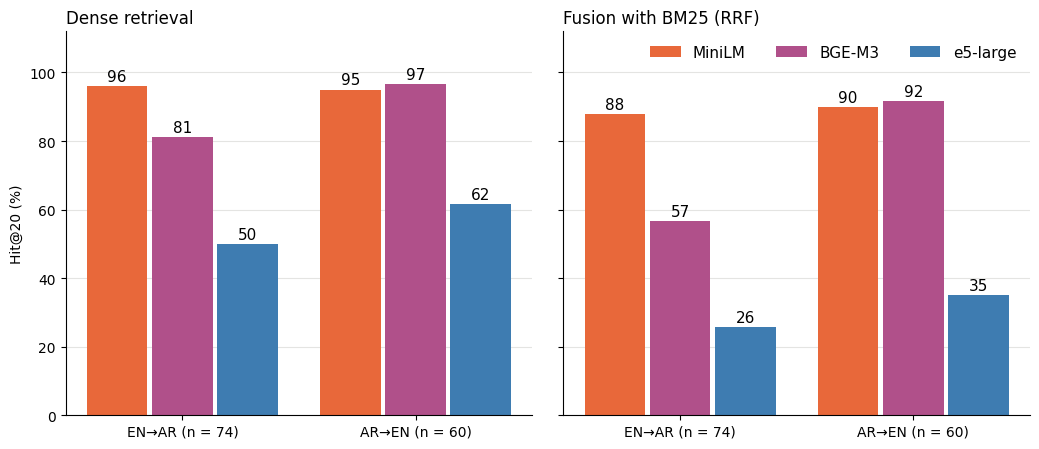

In [9]:
import glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
pc=pd.read_csv(glob.glob("/content/**/per_case_hits.csv",recursive=True)[0])
names={"MiniLM":"paraphrase-multilingual-MiniLM-L12-v2","BGE-M3":"bge-m3","e5-large":"multilingual-e5-large"}
cols={"MiniLM":"#e8683a","BGE-M3":"#b0508a","e5-large":"#3e7cb1"}
def rate(sys_,dr): g=pc[(pc.system==sys_)&(pc.direction==dr)]; return 100*g.hit_K20.mean()
fig,ax=plt.subplots(1,2,figsize=(10.5,4.6),sharey=True)
for a,(t,kind) in zip(ax,[("Dense retrieval","dense"),("Fusion with BM25 (RRF)","fusion")]):
    x=np.arange(2); w=.26
    for i,(lab,m) in enumerate(names.items()):
        v=[rate(f"{m}|{kind}",d) for d in ("EN→AR","AR→EN")]
        a.bar(x+(i-1)*(w+.02),v,w,color=cols[lab],label=lab)
        for xx,q in zip(x+(i-1)*(w+.02),v): a.text(xx,q+1.5,f"{q:.0f}",ha="center",fontsize=11)
    a.set_xticks(x); a.set_xticklabels(["EN→AR (n = 74)","AR→EN (n = 60)"]); a.set_title(t,loc="left"); a.set_ylim(0,112)
    a.yaxis.grid(True,color="#e4e4e2"); a.set_axisbelow(True)
    for s in ("top","right"): a.spines[s].set_visible(False)
ax[0].set_ylabel("Hit@20 (%)"); ax[1].legend(frameon=False,ncol=3,loc="upper right",fontsize=11)
plt.tight_layout(); plt.savefig("fig7_hit20_by_direction.png",dpi=200); plt.show()

## Cell 10 — Final check: paper values against computed values
Stops with an error if any value differs.

In [10]:
import glob, pandas as pd
pc=pd.read_csv(glob.glob("/content/**/per_case_hits.csv",recursive=True)[0])
M="paraphrase-multilingual-MiniLM-L12-v2"
EXPECT={ # (system, K) -> hits of 134 (paper Table A1); K=20 and K=1
 (f"{M}|dense",1):73,(f"{M}|dense",20):128,(f"{M}|fusion",1):6,(f"{M}|fusion",20):119,
 ("bge-m3|dense",1):59,("bge-m3|dense",20):118,("bge-m3|fusion",1):1,("bge-m3|fusion",20):97,
 ("multilingual-e5-large|dense",1):12,("multilingual-e5-large|dense",20):74,("multilingual-e5-large|fusion",1):0,("multilingual-e5-large|fusion",20):40}
DIRN={ # Table A3: (system, direction, K) -> hits
 (f"{M}|dense","EN→AR",20):71,(f"{M}|dense","AR→EN",20):57,(f"{M}|fusion","EN→AR",20):65,(f"{M}|fusion","AR→EN",20):54,
 ("bge-m3|dense","EN→AR",20):60,("bge-m3|dense","AR→EN",20):58,("multilingual-e5-large|dense","EN→AR",20):37,("multilingual-e5-large|dense","AR→EN",20):37}
bad=[]
for (s,K),v in EXPECT.items():
    got=int(pc[pc.system==s][f"hit_K{K}"].sum()); ok=got==v; print(("OK  " if ok else "DIFF"),s,f"K={K}",got,"expected",v); bad+= [] if ok else [(s,K)]
for (s,d,K),v in DIRN.items():
    got=int(pc[(pc.system==s)&(pc.direction==d)][f"hit_K{K}"].sum()); ok=got==v; print(("OK  " if ok else "DIFF"),s,d,f"K={K}",got,"expected",v); bad+= [] if ok else [(s,d,K)]
assert not bad, "values differ from the paper: "+str(bad)
print("\nAll checked values match the paper.")

OK   paraphrase-multilingual-MiniLM-L12-v2|dense K=1 73 expected 73
OK   paraphrase-multilingual-MiniLM-L12-v2|dense K=20 128 expected 128
OK   paraphrase-multilingual-MiniLM-L12-v2|fusion K=1 6 expected 6
OK   paraphrase-multilingual-MiniLM-L12-v2|fusion K=20 119 expected 119
OK   bge-m3|dense K=1 59 expected 59
OK   bge-m3|dense K=20 118 expected 118
OK   bge-m3|fusion K=1 1 expected 1
OK   bge-m3|fusion K=20 97 expected 97
OK   multilingual-e5-large|dense K=1 12 expected 12
OK   multilingual-e5-large|dense K=20 74 expected 74
OK   multilingual-e5-large|fusion K=1 0 expected 0
OK   multilingual-e5-large|fusion K=20 40 expected 40
OK   paraphrase-multilingual-MiniLM-L12-v2|dense EN→AR K=20 71 expected 71
OK   paraphrase-multilingual-MiniLM-L12-v2|dense AR→EN K=20 57 expected 57
OK   paraphrase-multilingual-MiniLM-L12-v2|fusion EN→AR K=20 65 expected 65
OK   paraphrase-multilingual-MiniLM-L12-v2|fusion AR→EN K=20 54 expected 54
OK   bge-m3|dense EN→AR K=20 60 expected 60
OK   bge-m3|de